<a href="https://colab.research.google.com/github/Dinithi-2000/J26-IT-381/blob/GamageIT23481244/CinnaSense_Image_Model_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive Connected!")


Mounted at /content/drive
Google Drive Connected!


In [2]:

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

drive_root = Path("/content/drive/MyDrive")

print("My Drive folders and files:")
for item in drive_root.iterdir():
    print(item.name)


Mounted at /content/drive
My Drive folders and files:
Getting started.pdf
file_1606360824PHT6205.pdf
file_1606982856Sinhala_medium.pdf
Schedule.gsheet
Untitled spreadsheet.gsheet
grade5_2020_sin1.gdoc
Screenshot_20211210-125122_Adobe Acrobat.jpg
Screenshot_20220102-091316_Adobe Acrobat.jpg
HNB_DL_RECEIPT_20220106_205113.pdf
CamScanner 01-28-2022 11.08_2.jpg
Emailing DOC-20220905-WA0003..pdf
selfie van.jpg
App_Backup_Restore
PUHAIJ20230729225534299000.pdf
malithi notice.pdf
Receipt356488020250131113444028000.pdf
PDF Bundle
Colab Notebooks
booking (1).drawio
Untitled Diagram.drawio
usecase Diagram.drawio
booking.drawio
Untitled Diagram1.drawio
WhatsApp Image 2025-05-15 at 22.57.10 (2).jpeg
WhatsApp Image 2025-05-15 at 22.57.10 (1).jpeg
WhatsApp Image 2025-05-15 at 23.11.59.jpeg
WhatsApp Image 2025-05-15 at 23.42.26 (3).jpeg
WhatsApp Image 2025-05-15 at 23.42.26 (1).jpeg
WhatsApp Image 2025-05-15 at 23.42.26 (2).jpeg
Google AI Studio
Dini Gamage CV.pdf
Dinithi Gamage CV.pdf
Lab 03.rar
Din

In [3]:

from pathlib import Path

dataset_folder = Path(
    "/content/drive/MyDrive/CinnaSense_Dataset"
)

if dataset_folder.exists():
    print("Dataset folder found!")
    for item in dataset_folder.iterdir():
        print(item.name)
else:
    print("Folder not found at this path.")
    print("Check the folder location in My Drive.")



Dataset folder found!
good_quality
Suspected Mold


In [4]:

from pathlib import Path

dataset_path = Path(
    "/content/drive/MyDrive/CinnaSense_Dataset"
)

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

total_images = 0

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        images = [
            f for f in folder.rglob("*")
            if f.is_file() and f.suffix.lower() in extensions
        ]

        print(f"{folder.name}: {len(images)} images")
        total_images += len(images)

print("------------------------")
print(f"Total Images: {total_images}")


Suspected Mold: 179 images
good_quality: 129 images
------------------------
Total Images: 308


In [5]:

import random
import shutil
from pathlib import Path

SOURCE = Path("/content/drive/MyDrive/CinnaSense_Dataset")
DEST = Path("/content/cinnamon_split")

random.seed(42)

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# Create a fresh split in Colab temporary storage
if DEST.exists():
    shutil.rmtree(DEST)

for class_folder in sorted(SOURCE.iterdir()):
    if not class_folder.is_dir():
        continue

    images = [
        p for p in class_folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    random.shuffle(images)

    n = len(images)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    splits = {
        "train": images[:train_end],
        "val": images[train_end:val_end],
        "test": images[val_end:]
    }

    for split_name, files in splits.items():
        output_dir = DEST / split_name / class_folder.name
        output_dir.mkdir(parents=True, exist_ok=True)

        for index, image in enumerate(files):
            output_name = f"{index:04d}_{image.name}"
            shutil.copy2(image, output_dir / output_name)

        print(
            f"{class_folder.name} | "
            f"{split_name}: {len(files)} images"
        )

print("\nDataset splitting completed!")


Suspected Mold | train: 125 images
Suspected Mold | val: 27 images
Suspected Mold | test: 27 images
good_quality | train: 90 images
good_quality | val: 19 images
good_quality | test: 20 images

Dataset splitting completed!


In [6]:

import tensorflow as tf
from pathlib import Path

DATA_DIR = Path("/content/cinnamon_split")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("\nClass Names:", class_names)
print("Number of Classes:", len(class_names))


Found 215 files belonging to 2 classes.
Found 46 files belonging to 2 classes.

Class Names: ['Suspected Mold', 'good_quality']
Number of Classes: 2


In [7]:

from tensorflow.keras import layers, Model

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# Data augmentation (training only)
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

print("Model Training Completed!")


Epoch 1/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.6000 - loss: 0.7282 - val_accuracy: 0.7391 - val_loss: 0.4766
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.6884 - loss: 0.5788 - val_accuracy: 0.7609 - val_loss: 0.4204
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.7535 - loss: 0.4688 - val_accuracy: 0.7609 - val_loss: 0.3998
Epoch 4/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.7860 - loss: 0.4220 - val_accuracy: 0.7826 - val_loss: 0.3877
Epoch 5/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.8233 - loss: 0.3858 - val_accuracy: 0.8478 - val_loss: 0.3681
Epoch 6/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.8605 - loss: 0.3343 - val_accuracy: 0.8043 - val_loss: 0.3686
Epoch 7/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.8651 - loss: 0.3337 - val_accuracy: 0.7826 - val_loss: 0.3571
Epoch 8/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.8326 - loss: 0.3424 - val_accuracy: 0.8478 - val_loss:

In [9]:

import tensorflow as tf

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/cinnamon_split/test",
    image_size=(224, 224),
    batch_size=16,
    shuffle=False
)

test_loss, test_accuracy = model.evaluate(test_ds)

print("\n===== CINNASENSE TEST RESULTS =====")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


Found 47 files belonging to 2 classes.
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.8298 - loss: 0.3346

===== CINNASENSE TEST RESULTS =====
Test Accuracy: 82.98%
Test Loss: 0.3346


3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step
Classes: ['Suspected Mold', 'good_quality']

Classification Report:
                precision    recall  f1-score   support

Suspected Mold       0.88      0.81      0.85        27
  good_quality       0.77      0.85      0.81        20

      accuracy                           0.83        47
     macro avg       0.83      0.83      0.83        47
  weighted avg       0.83      0.83      0.83        47



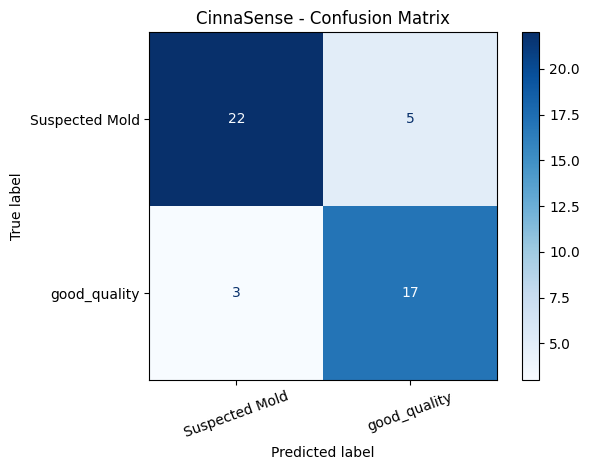

In [10]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

# Actual labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Model predictions
predictions = model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

# Confirm class order
print("Classes:", class_names)

# Precision, Recall and F1
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    values_format="d"
)

plt.title("CinnaSense - Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [11]:

import json
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/CinnaSense_Models")
save_dir.mkdir(parents=True, exist_ok=True)

model.save(save_dir / "cinnamon_quality_mobilenetv2.keras")

with open(save_dir / "class_names.json", "w") as f:
    json.dump(class_names, f)

print("Model saved successfully!")
print("Location:", save_dir)


Model saved successfully!
Location: /content/drive/MyDrive/CinnaSense_Models


Saving IMG_9614.jpeg to IMG_9614.jpeg


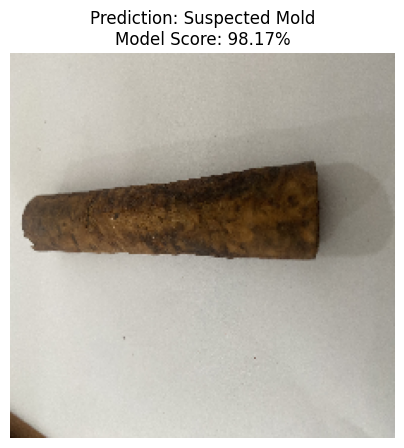

Predicted Class: Suspected Mold
Model Score: 98.17%


In [12]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import json

from google.colab import files
from pathlib import Path

# Load saved model and class names
save_dir = Path("/content/drive/MyDrive/CinnaSense_Models")

model = tf.keras.models.load_model(
    save_dir / "cinnamon_quality_mobilenetv2.keras"
)

with open(save_dir / "class_names.json", "r") as f:
    class_names = json.load(f)

# Upload a new cinnamon image
uploaded = files.upload()

for filename in uploaded.keys():

    img = tf.keras.utils.load_img(
        filename,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    predictions = model.predict(img_array, verbose=0)[0]

    predicted_index = int(np.argmax(predictions))
    predicted_class = class_names[predicted_index]
    confidence = float(predictions[predicted_index]) * 100

    # Display
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Model Score: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted Class:", predicted_class)
    print(f"Model Score: {confidence:.2f}%")
